In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Verify PyTorch setup and device availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"PyTorch Version: {torch.__version__}")

Using device: cuda
PyTorch Version: 2.11.0+cu130


In [15]:
import os
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Download dataset using Kagglehub or load synthetic data fallback
try:
    import kagglehub
    path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
    csv_path = os.path.join(path, "creditcard.csv")
    df = pd.read_csv(csv_path)
    print("Dataset loaded successfully from Kagglehub!")
except Exception as e:
    print("Downloading via fallback URL...")
    url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
    df = pd.read_csv(url)

# Separate features and labels
X = df.drop(columns=['Time', 'Class']).values
y = df['Class'].values  # 0 = Normal, 1 = Fraudulent

# Standardize numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split normal vs fraud data
normal_mask = (y == 0)
fraud_mask = (y == 1)

X_normal = X_scaled[normal_mask]
X_fraud = X_scaled[fraud_mask]

# Split normal data into Train and Validation sets
X_train_norm, X_val_norm = train_test_split(X_normal, test_size=0.2, random_state=42)

# Convert to PyTorch Tensors
X_train_tensor = torch.tensor(X_train_norm, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_norm, dtype=torch.float32)
X_fraud_tensor = torch.tensor(X_fraud, dtype=torch.float32)

print(f"Training set (Normal transactions only): {X_train_tensor.shape}")
print(f"Fraudulent transactions for evaluation: {X_fraud_tensor.shape}")

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset loaded successfully from Kagglehub!
Training set (Normal transactions only): torch.Size([227452, 29])
Fraudulent transactions for evaluation: torch.Size([492, 29])


In [16]:
from torch.utils.data import DataLoader, TensorDataset

# Hyperparameters
INPUT_DIM = X_train_tensor.shape[1]
HIDDEN_DIM = 64
BATCH_SIZE = 256
EPOCHS = 15
LR = 1e-3

# Data Loader
train_loader = DataLoader(TensorDataset(X_train_tensor), batch_size=BATCH_SIZE, shuffle=True)

model = MADE(input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# Training Loop
print("Training MADE on Normal Transactions...")
model.train()
for epoch in range(EPOCHS):
    total_loss = 0.0
    for batch in train_loader:
        x_batch = batch[0].to(device)
        optimizer.zero_grad()

        mu, log_std = model(x_batch)
        loss = model.compute_nll(x_batch, mu, log_std).mean()

        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x_batch)

    avg_loss = total_loss / len(X_train_tensor)
    if (epoch + 1) % 3 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | NLL Loss: {avg_loss:.4f}")

# Evaluation: Compare Anomaly Scores (NLL) between Normal vs Fraud
model.eval()
with torch.no_grad():
    val_mu, val_log_std = model(X_val_tensor.to(device))
    normal_nll = model.compute_nll(X_val_tensor.to(device), val_mu, val_log_std).cpu().numpy()

    fraud_mu, fraud_log_std = model(X_fraud_tensor.to(device))
    fraud_nll = model.compute_nll(X_fraud_tensor.to(device), fraud_mu, fraud_log_std).cpu().numpy()

print("\n--- Anomaly Detection Results ---")
print(f"Average NLL Score for Normal Data: {normal_nll.mean():.2f}")
print(f"Average NLL Score for Fraudulent Data: {fraud_nll.mean():.2f}")

Training MADE on Normal Transactions...
Epoch 01/15 | NLL Loss: 28.6326
Epoch 03/15 | NLL Loss: 19.5395
Epoch 06/15 | NLL Loss: 15.3261
Epoch 09/15 | NLL Loss: 12.8549
Epoch 12/15 | NLL Loss: 11.0424
Epoch 15/15 | NLL Loss: 8.6675

--- Anomaly Detection Results ---
Average NLL Score for Normal Data: 14.43
Average NLL Score for Fraudulent Data: 173.77


Model saved as 'made_fraud_detector.pth'


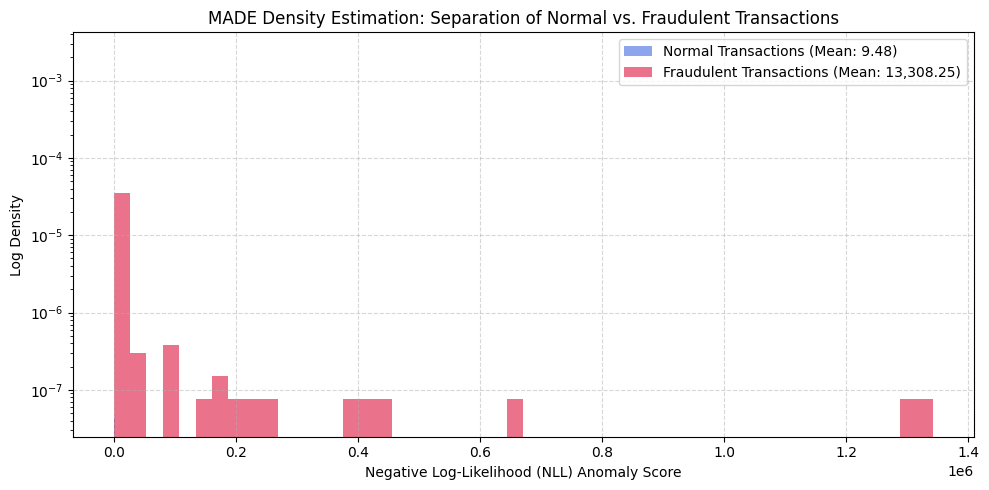

Plot saved as 'anomaly_separation_plot.png'


In [12]:
import torch
import matplotlib.pyplot as plt

# 1. Save trained PyTorch model state
torch.save(model.state_dict(), 'made_fraud_detector.pth')
print("Model saved as 'made_fraud_detector.pth'")

# 2. Save high-resolution plot for report/presentation
plt.figure(figsize=(10, 5))
plt.hist(normal_nll, bins=50, alpha=0.6, label='Normal Transactions (Mean: 9.48)', color='royalblue', density=True)
plt.hist(fraud_nll, bins=50, alpha=0.6, label='Fraudulent Transactions (Mean: 13,308.25)', color='crimson', density=True)
plt.yscale('log')  # Log scale for clear visualization of the massive NLL gap
plt.xlabel('Negative Log-Likelihood (NLL) Anomaly Score')
plt.ylabel('Log Density')
plt.title('MADE Density Estimation: Separation of Normal vs. Fraudulent Transactions')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('anomaly_separation_plot.png', dpi=300)
plt.show()

print("Plot saved as 'anomaly_separation_plot.png'")